<a href="https://colab.research.google.com/github/Mozassam/ML/blob/master/96_SVM_KernalTrick.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.axes._axes import _log as matplotlib_axes_logger
from mpl_toolkits import mplot3d
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from matplotlib.colors import ListedColormap

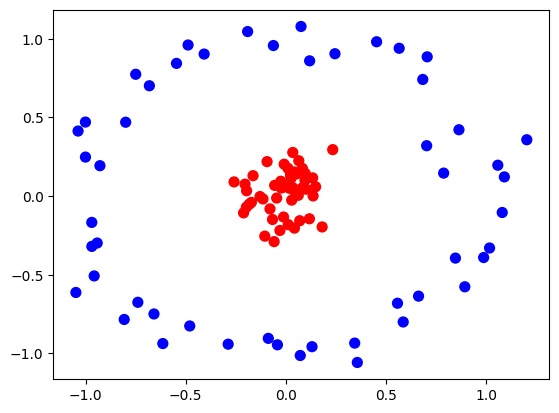

In [3]:
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='bwr')

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20)

In [5]:
classifier = SVC(kernel="linear")
classifier.fit(X_train, y_train.ravel())
y_pred = classifier.predict(X_test)

In [6]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.3

In [7]:
zero_one_colourmap = ListedColormap(('blue', 'red'))
def plot_decision_boundary(X, y, clf):
    X_set, y_set = X, y
    X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1,
                                 stop = X_set[:, 0].max() + 1,
                                 step = 0.01),
                       np.arange(start = X_set[:, 1].min() - 1,
                                 stop = X_set[:, 1].max() + 1,
                                 step = 0.01))

    plt.contourf(X1, X2, clf.predict(np.array([X1.ravel(),
                                             X2.ravel()]).T).reshape(X1.shape),
               alpha = 0.75,
               cmap = zero_one_colourmap)
    plt.xlim(X1.min(), X1.max())
    plt.ylim(X2.min(), X2.max())
    for i, j in enumerate(np.unique(y_set)):
        plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = (zero_one_colourmap)(i), label = j)
    plt.title('SVM Decision Boundary')
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.legend()
    return plt.show()

/tmp/ipykernel_3960/3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


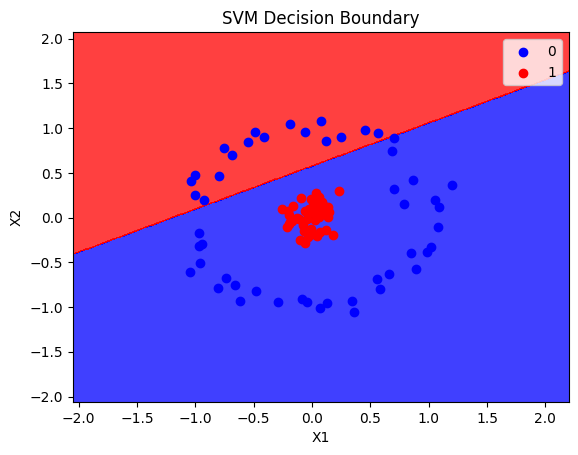

In [8]:
plot_decision_boundary(X, y, classifier)

In [9]:
def plot_3d_plot(X, y):
    r = np.exp(-(X ** 2).sum(1))
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=100, cmap='bwr')
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.set_zlabel('y')
    return ax

In [10]:
rbf_classifier = SVC(kernel="rbf")
rbf_classifier.fit(X_train, y_train)
y_pred = rbf_classifier.predict(X_test)

In [11]:
accuracy_score(y_test, y_pred)

1.0

/tmp/ipykernel_3960/3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


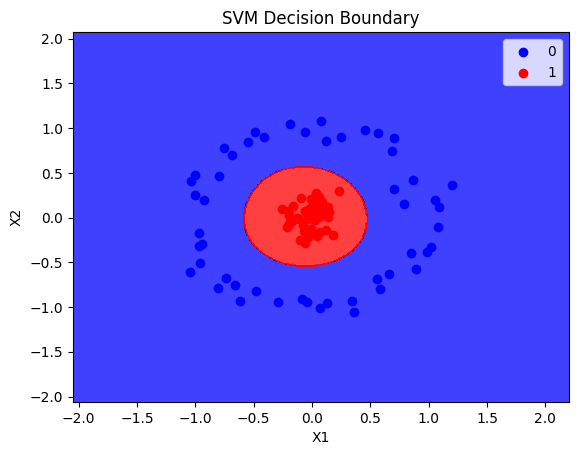

In [12]:
plot_decision_boundary(X, y, rbf_classifier)

In [13]:
poly_classifier = SVC(kernel="poly",degree=2)
poly_classifier.fit(X_train, y_train)
y_pred = poly_classifier.predict(X_test)

In [14]:
accuracy_score(y_test, y_pred)

1.0

/tmp/ipykernel_3960/3603277588.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


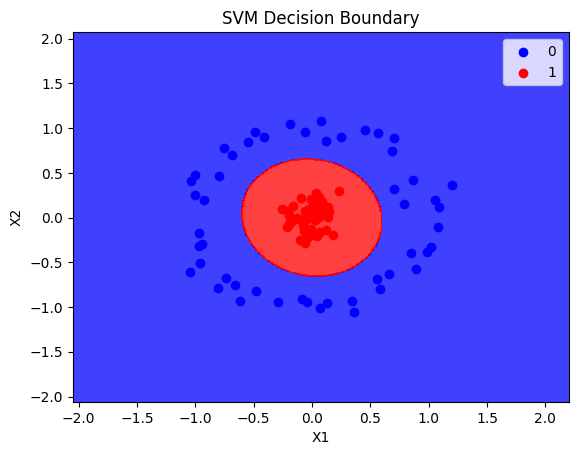

In [15]:
plot_decision_boundary(X, y, poly_classifier)

In [17]:
X

array([[-1.00028932e+00,  2.48085850e-01],
       [ 9.60728516e-02,  1.45049680e-01],
       [-1.97272348e-01, -7.02524728e-02],
       [ 5.27150868e-02,  1.41068433e-01],
       [-9.41789156e-01, -2.98366622e-01],
       [ 1.80979158e-01, -1.96203208e-01],
       [ 9.86911976e-01, -3.90539880e-01],
       [-4.79855754e-01, -8.25876808e-01],
       [-1.16761144e-02, -1.33220915e-01],
       [ 8.63645484e-01,  4.21841925e-01],
       [ 4.33535993e-02,  1.53188368e-01],
       [ 7.87347524e-01,  1.46157094e-01],
       [ 8.46070456e-01, -3.94292094e-01],
       [-9.68679180e-01, -1.67395920e-01],
       [ 2.58936974e-02,  1.13675157e-01],
       [ 1.00545703e-01,  4.38414293e-02],
       [-5.59593535e-02,  6.81605578e-02],
       [ 3.88460046e-02,  3.81508205e-02],
       [-7.38807966e-01, -6.75323044e-01],
       [-1.03724995e+00,  4.13743959e-01],
       [-1.72422248e-01, -4.01216780e-02],
       [-5.87929577e-02, -2.89623962e-01],
       [-4.21903829e-02, -9.45712265e-01],
       [-2.

In [18]:
np.exp(-(X**2)).sum(1)

array([1.30797574, 1.96999285, 1.95690788, 1.97752138, 1.3267281 ,
       1.93001297, 1.23611205, 1.29989394, 1.98227243, 1.31129881,
       1.97492876, 1.51685421, 1.34479966, 1.36364463, 1.98649083,
       1.98802127, 1.99223836, 1.9970377 , 1.21313158, 1.18366146,
       1.96909969, 1.91608907, 1.40708597, 1.99682794, 1.38241126,
       1.98667595, 1.20392733, 1.95971609, 1.92615478, 1.99849746,
       1.02030002, 1.36195353, 1.98341537, 1.98292916, 1.10085521,
       1.2898847 , 1.94506319, 1.96930304, 1.98174192, 1.06183002,
       1.9524949 , 1.9610827 , 1.17316444, 1.39606793, 1.95759391,
       1.51283806, 1.92718619, 1.13974301, 1.35283193, 1.30089362,
       1.38283641, 1.97470191, 1.33225166, 1.96271708, 1.25264891,
       1.99655269, 1.99055744, 1.99719708, 1.92470016, 1.29879885,
       1.97102761, 1.16759463, 1.11903289, 1.16886937, 1.96404308,
       1.96733739, 1.3296597 , 1.20716564, 1.11512271, 1.19646949,
       1.99772285, 1.97369315, 1.28894144, 1.21854322, 1.23285

In [19]:
X_new=np.exp(-(X**2))

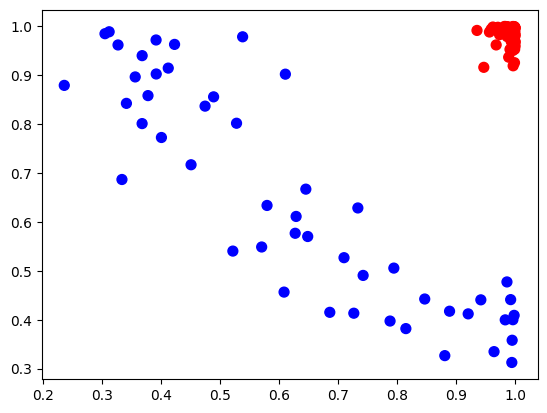

In [20]:
plt.scatter(X_new[:, 0], X_new[:, 1], c=y, s=50, cmap='bwr')